# Figure 6 - compatibility matrix of viability assays

In [ ]:
from itertools import combinations
from pathlib import Path
import re

import numpy as np
import pandas as pd

# input dataset and output folder, relative to the folder of the notebooks
DATA = Path("../1_pipeline/Final_dataset/dataset_final.xlsx")   # final dataset, output of the pipeline (2862 records)
OUT = Path("results")
OUT.mkdir(parents=True, exist_ok=True)
VALUE_COL, ASSAY_COL, FAMILY_COL = "Cell_Viability (%)", "Test_norm", "Test_family"
# short assay labels of Figure 3 (the column Test_norm of the source schema is not part of the final dataset)
ASSAY_LABELS = {'MTT': 'mtt', 'CellTiterBlue': 'celltiterblue', 'XTT': 'xtt', 'LDH': 'ldh', 'Live/Dead': 'live/dead', 'MTS': 'mts', 'NRU': 'nru', 'WST-8/CCK-8': 'wst-8', 'AlamarBlue': 'alamarblue', 'CVS': 'cvs', 'WST-1': 'wst-1', 'CellTiter-Glo': 'celltiterglo', 'EZ4U': 'ez4u', 'ATPLite': 'atplite', 'ApoTox-Glo Triplex': 'apotox-glo triplex', 'ViaLight': 'vialight', 'ATP': 'atp'}
def condition_cols(d):
    return ["Material", "Dry_Diameter (nm)", "Zeta_in_Water (mV)", "Cell_Type", "Cancer", "Concentration (g/l)2",
            "Coat/Functional Group", "Animal_mapped_combined", "Cell_organ", "Time (hr)"]

def condition_key(d, cols, missing_matches=True):
    w = d[cols]
    if not missing_matches:
        return pd.Series(np.where(w.notna().all(axis=1), w.astype(str).agg(" | ".join, axis=1), None), index=d.index)
    return w.astype(object).where(w.notna(), "<missing>").astype(str).agg(" | ".join, axis=1)

import matplotlib.pyplot as plt
from matplotlib import transforms as mtransforms
from matplotlib.patches import Patch, Rectangle

MIN_COMPARISONS = 2
CRITERIA = {"good": {"mean_max": 15, "max_max": 30}, "moderate": {"mean_max": 25, "max_max": 50}}
COLORS = {"good": "#90EE90", "moderate": "#FFD700", "poor": "#FF6B6B", "no_data": "#D3D3D3", "diagonal": "#FFFFFF"}
LABELS = {"good": "MERGEABLE", "moderate": "CAUTION", "poor": "DO NOT MERGE", "no_data": "NOT ENOUGH DATA"}
FAMILY_ORDER = ["ATP luciferase", "Crystal Violet", "LDH", "Live/Dead", "Neutral Red", "Protease (ApoTox-Glo)", "Resazurin", "Tetrazolium"]

def verdict(mean_diff, max_diff, n):
    if n < MIN_COMPARISONS:
        return "no_data"
    if mean_diff <= CRITERIA["good"]["mean_max"] and max_diff <= CRITERIA["good"]["max_max"]:
        return "good"
    if mean_diff <= CRITERIA["moderate"]["mean_max"] and max_diff <= CRITERIA["moderate"]["max_max"]:
        return "moderate"
    return "poor"

def pair_table(d, cols=None, missing_matches=True, extra=()):
    """all assay pairs compared under identical conditions: n comparisons, publications, mean / max absolute difference, verdict"""
    cols = list(cols or condition_cols(d)) + list(extra)
    w = d.dropna(subset=[ASSAY_COL, VALUE_COL]).copy()
    w["_cond"] = condition_key(w, cols, missing_matches)
    w = w[w["_cond"].notna()]
    acc = {}
    for _, g in w.groupby("_cond", sort=False):
        means = g.groupby(ASSAY_COL)[VALUE_COL].mean()
        for (a, va), (b, vb) in combinations(means.items(), 2):
            r = acc.setdefault(tuple(sorted((a, b))), {"diffs": [], "dois": set(), "cross_publication": 0})
            r["diffs"].append(abs(va - vb))
            da, db = set(g.loc[g[ASSAY_COL] == a, "DOI"]), set(g.loc[g[ASSAY_COL] == b, "DOI"])
            r["dois"] |= da | db
            r["cross_publication"] += int(not (da & db))      # the two assays of this condition come from different publications
    rows = [{"assay_A": a, "assay_B": b, "n_comparisons": len(r["diffs"]), "n_publications": len(r["dois"]),
             "cross_publication_comparisons": r["cross_publication"], "mean_abs_diff": np.mean(r["diffs"]),
             "max_abs_diff": np.max(r["diffs"]), "verdict": verdict(np.mean(r["diffs"]), np.max(r["diffs"]), len(r["diffs"]))}
            for (a, b), r in sorted(acc.items())]
    return pd.DataFrame(rows)

def assay_order(d):
    pairs = d[[ASSAY_COL, FAMILY_COL]].dropna().drop_duplicates()
    assert not pairs[ASSAY_COL].duplicated().any(), "an assay belongs to two families"
    pairs["rank"] = pairs[FAMILY_COL].map(lambda f: FAMILY_ORDER.index(f) if f in FAMILY_ORDER else len(FAMILY_ORDER))
    pairs = pairs.sort_values(["rank", FAMILY_COL, ASSAY_COL])
    order, spans = pairs[ASSAY_COL].tolist(), []
    for fam, g in pairs.groupby(FAMILY_COL, sort=False):
        idx = [order.index(a) for a in g[ASSAY_COL]]
        spans.append((fam, min(idx), max(idx)))
    return order, spans

def wrap(text, width):
    lines, cur = [], ""
    for word in str(text).split():
        if cur and len(cur) + 1 + len(word) > width:
            lines.append(cur); cur = word
        else:
            cur = f"{cur} {word}".strip()
    return "\n".join(lines + [cur] if cur else lines)

def plot_matrix(d, tab, path=None, show_publications=True):
    names, spans = assay_order(d.dropna(subset=[ASSAY_COL, VALUE_COL]))
    n = len(names); idx = {a: i for i, a in enumerate(names)}
    cell = {}
    for r in tab.itertuples():
        cell[(idx[r.assay_A], idx[r.assay_B])] = cell[(idx[r.assay_B], idx[r.assay_A])] = r
    fig, ax = plt.subplots(figsize=(12, 11), facecolor="white")
    plt.subplots_adjust(left=0.3, right=0.98, bottom=0.2, top=0.98)
    for i in range(n):
        for j in range(i + 1):
            y = n - 1 - i
            r = cell.get((i, j))
            v = "diagonal" if i == j else (r.verdict if r is not None else "no_data")
            ax.add_patch(Rectangle((j, y), 1, 1, facecolor=COLORS[v], edgecolor="#555555", linewidth=0.65))
            if i == j:
                ax.plot([j, j + 1], [y + 1, y], color="#DDDDDD", linewidth=1.0)
            elif r is not None and v != "no_data":
                ax.text(j + 0.5, y + 0.58 if show_publications else y + 0.5, str(r.n_comparisons), ha="center", va="center", fontsize=10, fontweight="bold")
                if show_publications:
                    ax.text(j + 0.5, y + 0.25, f"({r.n_publications})", ha="center", va="center", fontsize=8)
    disp = [re.sub(r"\s+", " ", a.replace("-", " ").replace("/", " ")).strip() for a in names]
    ax.set_xlim(0, n); ax.set_ylim(0, n); ax.set_aspect("equal")
    ax.set_xticks(np.arange(n) + 0.5); ax.set_yticks(np.arange(n) + 0.5)
    fs = 11 if n <= 18 else 9
    # assay names in normal weight, like the category labels of the other figures (bold: group headings and the legend title)
    ax.set_xticklabels([wrap(s, 12) for s in disp], rotation=60, ha="right", fontsize=fs)
    ax.set_yticklabels([wrap(s, 12) for s in disp[::-1]], fontsize=fs)
    ax.tick_params(axis="both", length=0)
    for s in ax.spines.values():
        s.set_visible(False)                      # no square frame around the triangle
    leg = ax.legend(handles=[Patch(facecolor=COLORS[k], edgecolor="#555555", label=l) for k, l in LABELS.items()], title="Verdict",
                    loc="upper right", bbox_to_anchor=(1.0, 1.0), frameon=True, fancybox=True, shadow=True, fontsize=12, title_fontsize=13)
    leg.get_title().set_fontweight("bold")
    fig.canvas.draw()
    to_axes = ax.transAxes.inverted()
    if show_publications:                         # under the legend, in the empty upper triangle
        lb = leg.get_window_extent().transformed(to_axes)
        ax.text(lb.x0, lb.y0 - 0.02, "Cell: number of comparisons\n(number of publications)", transform=ax.transAxes,
                fontsize=10, va="top")
    xb = min(t.get_window_extent().transformed(to_axes).x0 for t in ax.get_yticklabels()) - 0.015   # left of the row labels
    trans = mtransforms.blended_transform_factory(ax.transAxes, ax.transData)
    for fam, s, e in spans:
        y0, y1 = n - (e + 1), n - s
        ax.plot([xb, xb], [y0, y1], transform=trans, clip_on=False, color="black", linewidth=1.8)
        for yy in (y0, y1):
            ax.plot([xb, xb - 0.035], [yy, yy], transform=trans, clip_on=False, color="black", linewidth=1.8)
        ax.text(xb - 0.055, (y0 + y1) / 2, wrap(fam, 14), transform=trans, ha="right", va="center", fontsize=14, fontweight="bold")
    if path:
        fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

## 1. Figure 3

Figure 3 for the manuscript: each cell shows the number of comparisons and, below, the number of publications they come from.
The matrix is symmetric, so only its lower triangle is drawn (each pair of assays once).

records: 2862 | assays with viability: 17 | assay pairs compared: 19 | comparisons: 621
comparisons whose two assays come from different publications: 0


,assay_A,assay_B,n_comparisons,n_publications,cross_publication_comparisons,mean_abs_diff,max_abs_diff,verdict
0,alamarblue,ldh,9,2,0,20.3,69.5,poor
1,alamarblue,live/dead,3,1,0,4.0,4.5,good
2,alamarblue,mtt,51,2,0,7.8,36.5,moderate
3,alamarblue,nru,48,1,0,21.1,42.6,moderate
4,apotox-glo triplex,celltiterglo,12,1,0,7.8,15.2,good
5,apotox-glo triplex,ldh,12,1,0,7.7,20.7,good
6,atp,ldh,173,1,0,12.5,65.3,poor
7,atp,mts,4,1,0,21.4,31.1,moderate
8,celltiterblue,ldh,4,1,0,8.6,12.1,good
9,celltiterblue,live/dead,4,1,0,7.4,12.9,good


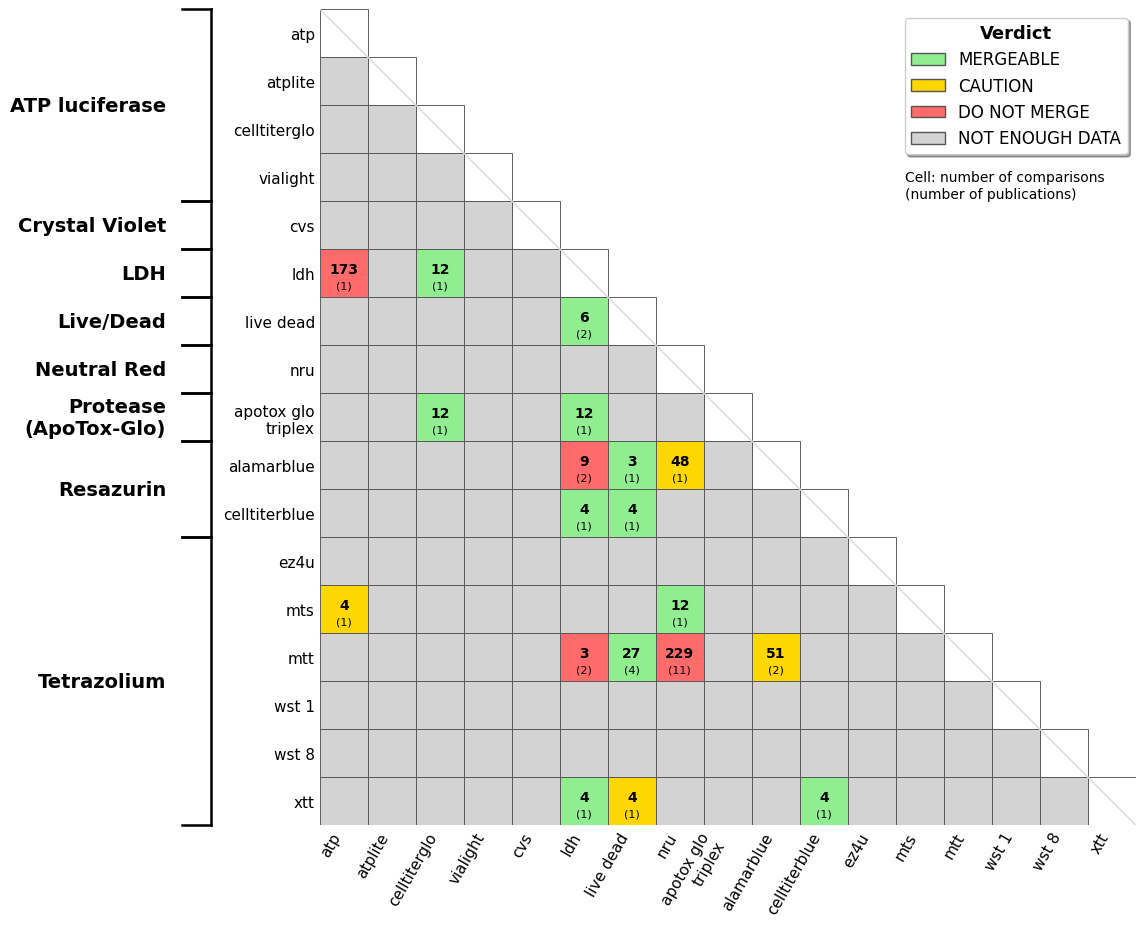

In [ ]:
D = pd.read_excel(DATA)
if "Test_norm" not in D:            # short assay labels of the figure
    D["Test_norm"] = D["Test"].map(ASSAY_LABELS)
    assert D["Test_norm"].notna().all(), sorted(set(D.loc[D.Test_norm.isna(), "Test"]))
tab = pair_table(D)
tab.to_csv(OUT / "Figure_3_assay_compatibility_pairs.csv", index=False)
print(f"records: {len(D)} | assays with viability: {D[ASSAY_COL].nunique()} | assay pairs compared: {len(tab)} | comparisons: {tab.n_comparisons.sum()}")
print("comparisons whose two assays come from different publications:", tab.cross_publication_comparisons.sum())
display(tab.round(1))
plot_matrix(D, tab, OUT / "Figure_3_assay_compatibility_matrix.png")

## 2. Sensitivity of the verdicts

In [ ]:
base = tab.set_index(["assay_A", "assay_B"])
variants = {
    "+ publication": pair_table(D, extra=["DOI"]),
    "strict (no missing descriptors)": pair_table(D, missing_matches=False),
}
sens = base[["n_comparisons", "n_publications", "verdict"]].copy()
for k, v in variants.items():
    v = v.set_index(["assay_A", "assay_B"])
    sens[f"n | {k}"] = v.n_comparisons.reindex(sens.index)
    sens[f"verdict | {k}"] = v.verdict.reindex(sens.index).fillna("(no comparison)")
sens.to_csv(OUT / "Figure_3_sensitivity.csv")
for k in variants:
    print(f"{k}: verdict changed for {(sens['verdict'] != sens[f'verdict | {k}']).sum()} of {len(sens)} pairs")
display(sens)

+ publication: verdict changed for 0 of 19 pairs
strict (no missing descriptors): verdict changed for 5 of 19 pairs


n_comparisons  n_publications   verdict  \
assay_A            assay_B                                                 
alamarblue         ldh                       9               2      poor   
                   live/dead                 3               1      good   
                   mtt                      51               2  moderate   
                   nru                      48               1  moderate   
apotox-glo triplex celltiterglo             12               1      good   
                   ldh                      12               1      good   
atp                ldh                     173               1      poor   
                   mts                       4               1  moderate   
celltiterblue      ldh                       4               1      good   
                   live/dead                 4               1      good   
                   xtt                       4               1      good   
celltiterglo       ldh                      12               1      good   
ldh                live/dead                 6               2      good   
                   mtt                       3               2      poor   
                   xtt                       4               1      good   
live/dead          mtt                      27               4      good   
                   xtt                       4               1  moderate   
mts                nru                      12               1      good   
mtt                nru                     229              11      poor   

                                 n | + publication verdict | + publication  \
assay_A            assay_B                                                   
alamarblue         ldh                           9                    poor   
                   live/dead                     3                    good   
                   mtt                          51                moderate   
                   nru                          48                moderate   
apotox-glo triplex celltiterglo                 12                    good   
                   ldh                          12                    good   
atp                ldh                         173                    poor   
                   mts                           4                moderate   
celltiterblue      ldh                           4                    good   
                   live/dead                     4                    good   
                   xtt                           4                    good   
celltiterglo       ldh                          12                    good   
ldh                live/dead                     6                    good   
                   mtt                           3                    poor   
                   xtt                           4                    good   
live/dead          mtt                          27                    good   
                   xtt                           4                moderate   
mts                nru                          12                    good   
mtt                nru                         229                    poor   

                                 n | strict (no missing descriptors)  \
assay_A            assay_B                                             
alamarblue         ldh                                           NaN   
                   live/dead                                     NaN   
                   mtt                                          48.0   
                   nru                                          48.0   
apotox-glo triplex celltiterglo                                 12.0   
                   ldh                                          12.0   
atp                ldh                                         173.0   
                   mts                                           NaN   
celltiterblue      ldh                                           4.0   
     

In [ ]:
one_pub = tab[(tab.verdict != "no_data") & (tab.n_publications == 1)]
print(f"verdicts resting on a single publication: {len(one_pub)} of {(tab.verdict != 'no_data').sum()}")
display(one_pub[["assay_A", "assay_B", "n_comparisons", "verdict", "mean_abs_diff", "max_abs_diff"]].round(1))

verdicts resting on a single publication: 13 of 19


,assay_A,assay_B,n_comparisons,verdict,mean_abs_diff,max_abs_diff
1,alamarblue,live/dead,3,good,4.0,4.5
3,alamarblue,nru,48,moderate,21.1,42.6
4,apotox-glo triplex,celltiterglo,12,good,7.8,15.2
5,apotox-glo triplex,ldh,12,good,7.7,20.7
6,atp,ldh,173,poor,12.5,65.3
7,atp,mts,4,moderate,21.4,31.1
8,celltiterblue,ldh,4,good,8.6,12.1
9,celltiterblue,live/dead,4,good,7.4,12.9
10,celltiterblue,xtt,4,good,11.2,15.8
11,celltiterglo,ldh,12,good,7.8,22.4
